In [2]:

from pathlib import Path
import pandas as pd
import numpy as np

# Automatically find the AirWise project root
PROJECT_ROOT = next(
    (
        p for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "data" / "raw" / "AirQualityUCI.csv").is_file()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find AirQualityUCI.csv inside data/raw. "
        "Please check that the dataset exists."
    )

# Load original dataset
RAW_FILE = PROJECT_ROOT / "data" / "raw" / "AirQualityUCI.csv"

df = pd.read_csv(RAW_FILE, sep=";", decimal=",")

# Remove completely empty rows and columns
df = df.dropna(axis=0, how="all")
df = df.dropna(axis=1, how="all")

# Replace missing-value code
df = df.replace(-200, np.nan)

# Create datetime column
df["Datetime"] = pd.to_datetime(
    df["Date"].astype(str) + " " + df["Time"].astype(str),
    format="%d/%m/%Y %H.%M.%S",
    errors="coerce"
)

# Remove original date and time columns
df = df.drop(columns=["Date", "Time"])

# Sort by date and time
df = df.sort_values("Datetime").reset_index(drop=True)

print("AIRWISE DATASET LOADED SUCCESSFULLY")
print("-" * 45)
print("Project folder:", PROJECT_ROOT)
print("Dataset shape:", df.shape)
print("First timestamp:", df["Datetime"].min())
print("Last timestamp:", df["Datetime"].max())
print("\nDataset columns:")
print(df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())


AIRWISE DATASET LOADED SUCCESSFULLY
---------------------------------------------
Project folder: c:\Users\mayan\OneDrive\Desktop\AIRWISE
Dataset shape: (9357, 14)
First timestamp: 2004-03-10 18:00:00
Last timestamp: 2005-04-04 14:00:00

Dataset columns:
['CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'Datetime']

Missing values:
CO(GT)           1683
PT08.S1(CO)       366
NMHC(GT)         8443
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1639
PT08.S3(NOx)      366
NO2(GT)          1642
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
Datetime            0
dtype: int64


In [3]:

# Create a separate modeling dataset
# Keep the original df unchanged

model_data = df.drop(columns=["NMHC(GT)"]).copy()

# Ensure records are in chronological order
model_data = model_data.sort_values("Datetime").reset_index(drop=True)

# Check data quality
time_difference = model_data["Datetime"].diff()

print("AIRWISE MODELING DATA CHECK")
print("-" * 45)

print("Total observations:", len(model_data))
print("Total features including Datetime:", len(model_data.columns))

print(
    "Duplicate timestamps:",
    model_data["Datetime"].duplicated().sum()
)

print(
    "Time gaps other than one hour:",
    (time_difference.dropna() != pd.Timedelta(hours=1)).sum()
)

print("\nMissing value percentages:")
missing_percentage = (
    model_data.isnull().mean() * 100
).sort_values(ascending=False)

print(missing_percentage.round(2))

print("\nModeling dataset shape:", model_data.shape)


AIRWISE MODELING DATA CHECK
---------------------------------------------
Total observations: 9357
Total features including Datetime: 13
Duplicate timestamps: 0
Time gaps other than one hour: 0

Missing value percentages:
CO(GT)           17.99
NO2(GT)          17.55
NOx(GT)          17.52
C6H6(GT)          3.91
PT08.S1(CO)       3.91
PT08.S2(NMHC)     3.91
PT08.S3(NOx)      3.91
PT08.S4(NO2)      3.91
PT08.S5(O3)       3.91
T                 3.91
RH                3.91
AH                3.91
Datetime          0.00
dtype: float64

Modeling dataset shape: (9357, 13)


In [4]:

# STEP 7: FEATURE ENGINEERING FOR NEXT-HOUR CO FORECASTING

# Work with a separate copy
forecast_data = model_data.copy()

# Create the timestamp we want to predict
forecast_data["ForecastDatetime"] = (
    forecast_data["Datetime"] + pd.Timedelta(hours=1)
)

# Create historical CO features
# Lag 1 = most recently observed CO value
forecast_data["CO_lag_1"] = forecast_data["CO(GT)"]
forecast_data["CO_lag_2"] = forecast_data["CO(GT)"].shift(1)
forecast_data["CO_lag_3"] = forecast_data["CO(GT)"].shift(2)
forecast_data["CO_lag_24"] = forecast_data["CO(GT)"].shift(23)

# Create the next-hour CO target
next_timestamp = forecast_data["Datetime"].shift(-1)

is_next_hour = (
    next_timestamp - forecast_data["Datetime"]
) == pd.Timedelta(hours=1)

forecast_data["CO_next_hour"] = (
    forecast_data["CO(GT)"].shift(-1).where(is_next_hour)
)

# Create calendar features for the forecast hour
forecast_hour = forecast_data["ForecastDatetime"].dt.hour
forecast_day = forecast_data["ForecastDatetime"].dt.dayofweek
forecast_month = forecast_data["ForecastDatetime"].dt.month

forecast_data["Hour_sin"] = np.sin(2 * np.pi * forecast_hour / 24)
forecast_data["Hour_cos"] = np.cos(2 * np.pi * forecast_hour / 24)

forecast_data["Day_sin"] = np.sin(2 * np.pi * forecast_day / 7)
forecast_data["Day_cos"] = np.cos(2 * np.pi * forecast_day / 7)

forecast_data["Month_sin"] = np.sin(2 * np.pi * forecast_month / 12)
forecast_data["Month_cos"] = np.cos(2 * np.pi * forecast_month / 12)

# Select predictor columns
feature_columns = [
    "PT08.S1(CO)",
    "C6H6(GT)",
    "PT08.S2(NMHC)",
    "NOx(GT)",
    "PT08.S3(NOx)",
    "NO2(GT)",
    "PT08.S4(NO2)",
    "PT08.S5(O3)",
    "T",
    "RH",
    "AH",
    "CO_lag_1",
    "CO_lag_2",
    "CO_lag_3",
    "CO_lag_24",
    "Hour_sin",
    "Hour_cos",
    "Day_sin",
    "Day_cos",
    "Month_sin",
    "Month_cos"
]

# Keep only rows with an actual next-hour CO measurement.
# Missing predictor values are intentionally retained for now.
valid_rows = forecast_data["CO_next_hour"].notna()

X = forecast_data.loc[valid_rows, feature_columns].copy()
y = forecast_data.loc[valid_rows, "CO_next_hour"].copy()

forecast_dates = forecast_data.loc[
    valid_rows, "ForecastDatetime"
].copy()

# Split chronologically: first 80% for training, last 20% for testing
split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

train_dates = forecast_dates.iloc[:split_index]
test_dates = forecast_dates.iloc[split_index:]

# Display results
print("AIRWISE FORECASTING DATASET")
print("=" * 50)

print("Total usable target observations:", len(X))
print("Number of features:", len(feature_columns))

print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining period:")
print(train_dates.min(), "to", train_dates.max())

print("\nTesting period:")
print(test_dates.min(), "to", test_dates.max())

print("\nMissing predictor values in training data:",
      X_train.isnull().sum().sum())

print("Missing predictor values in testing data:",
      X_test.isnull().sum().sum())

print("\nTarget variable: CO concentration one hour ahead")
print("Target unit: mg/m³")


AIRWISE FORECASTING DATASET
Total usable target observations: 7673
Number of features: 21

Training data: (6138, 21)
Testing data: (1535, 21)

Training period:
2004-03-10 19:00:00 to 2005-01-29 06:00:00

Testing period:
2005-01-29 07:00:00 to 2005-04-04 14:00:00

Missing predictor values in training data: 4074
Missing predictor values in testing data: 853

Target variable: CO concentration one hour ahead
Target unit: mg/m³


C:\Users\mayan\AppData\Local\Temp\ipykernel_11080\2664217880.py:31: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  forecast_day = forecast_data["ForecastDatetime"].dt.dayofweek


In [5]:

# STEP 8: TRAIN AND EVALUATE THE FORECASTING MODEL

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

# 1. Build a pipeline.
# The imputer learns median values from TRAINING data only.
model_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# 2. Train the model
print("Training AirWise Random Forest model...")

model_pipeline.fit(X_train, y_train)

print("Model training completed!")

# 3. Predict CO concentration for the test period
rf_predictions = model_pipeline.predict(X_test)

# 4. Evaluate on the complete test set
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

# 5. Create a persistence baseline.
# This predicts that next-hour CO will equal the current-hour CO.
# Compare both models on exactly the same test observations.
baseline_mask = X_test["CO_lag_1"].notna()

y_test_common = y_test.loc[baseline_mask]
rf_common_predictions = pd.Series(
    rf_predictions,
    index=X_test.index
).loc[baseline_mask]

baseline_predictions = X_test.loc[
    baseline_mask, "CO_lag_1"
]

baseline_mae = mean_absolute_error(
    y_test_common, baseline_predictions
)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test_common, baseline_predictions)
)
baseline_r2 = r2_score(
    y_test_common, baseline_predictions
)

rf_common_mae = mean_absolute_error(
    y_test_common, rf_common_predictions
)
rf_common_rmse = np.sqrt(
    mean_squared_error(y_test_common, rf_common_predictions)
)
rf_common_r2 = r2_score(
    y_test_common, rf_common_predictions
)

# 6. Display evaluation results
print("\n" + "=" * 55)
print("AIRWISE MODEL EVALUATION")
print("=" * 55)

print("\nRandom Forest — Complete Test Set")
print(f"MAE:  {rf_mae:.4f} mg/m³")
print(f"RMSE: {rf_rmse:.4f} mg/m³")
print(f"R²:   {rf_r2:.4f}")

print("\nFAIR MODEL COMPARISON")
print("Both models evaluated on the same observations.")
print("Comparison observations:", len(y_test_common))

comparison = pd.DataFrame({
    "Model": ["Random Forest", "Persistence Baseline"],
    "MAE": [rf_common_mae, baseline_mae],
    "RMSE": [rf_common_rmse, baseline_rmse],
    "R2": [rf_common_r2, baseline_r2]
})

print(comparison.to_string(index=False))

# 7. Identify the most important features
importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": model_pipeline.named_steps["model"].feature_importances_
}).sort_values("Importance", ascending=False)

print("\nTOP 10 IMPORTANT FEATURES")
print(importance.head(10).to_string(index=False))

# 8. Save the validated model separately.
# Do NOT overwrite the existing model used by the dashboard API.
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_bundle = {
    "model": model_pipeline,
    "feature_columns": feature_columns,
    "target": "CO_next_hour",
    "forecast_horizon_hours": 1,
    "test_metrics": {
        "mae": float(rf_mae),
        "rmse": float(rf_rmse),
        "r2": float(rf_r2)
    }
}

validated_model_path = MODEL_DIR / "airwise_co_forecast_validated.joblib"
joblib.dump(model_bundle, validated_model_path)

print("\nValidated model saved to:")
print(validated_model_path)


Training AirWise Random Forest model...
Model training completed!

AIRWISE MODEL EVALUATION

Random Forest — Complete Test Set
MAE:  0.4087 mg/m³
RMSE: 0.5903 mg/m³
R²:   0.8073

FAIR MODEL COMPARISON
Both models evaluated on the same observations.
Comparison observations: 1510
               Model      MAE     RMSE       R2
       Random Forest 0.410191 0.592204 0.805540
Persistence Baseline 0.514834 0.796790 0.647973

TOP 10 IMPORTANT FEATURES
      Feature  Importance
     CO_lag_1    0.616837
PT08.S2(NMHC)    0.095839
     Hour_sin    0.043273
     Hour_cos    0.039828
    CO_lag_24    0.024394
      NOx(GT)    0.020319
     CO_lag_2    0.018750
     C6H6(GT)    0.018099
  PT08.S1(CO)    0.017828
  PT08.S5(O3)    0.013102

Validated model saved to:
c:\Users\mayan\OneDrive\Desktop\AIRWISE\models\airwise_co_forecast_validated.joblib


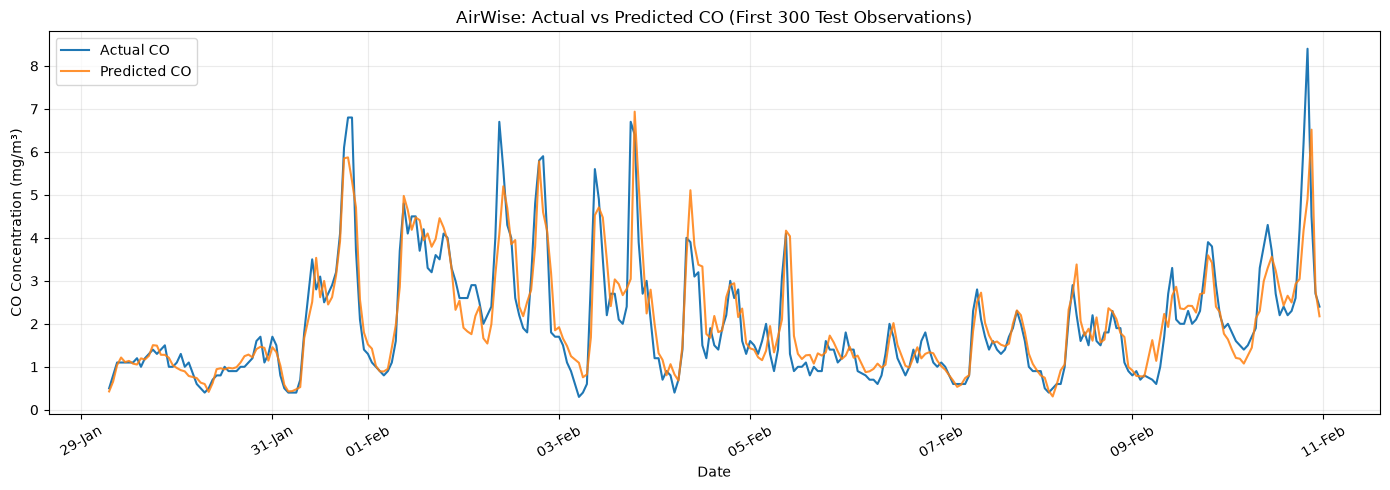

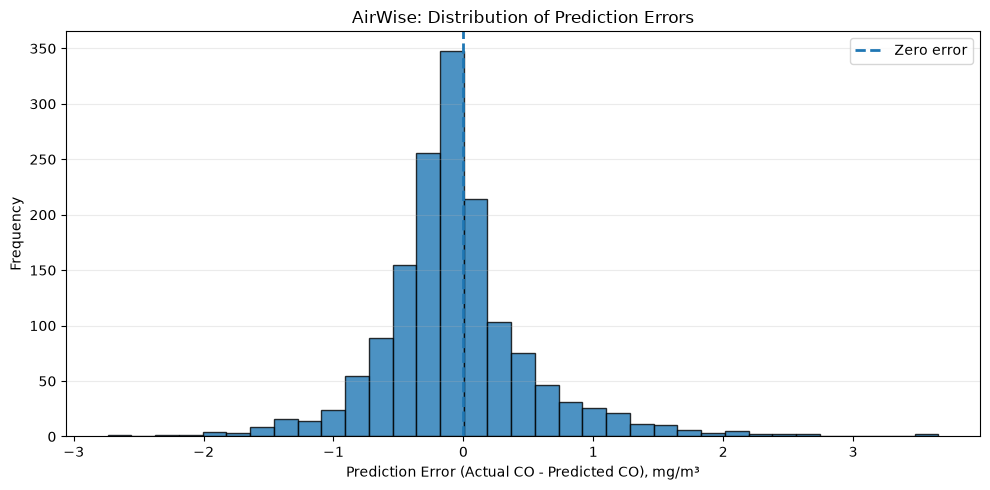

VISUALIZATION AND EXPORT COMPLETE
Saved files:
- actual_vs_predicted_co.png
- prediction_error_distribution.png
- airwise_test_predictions.csv

Output folder: c:\Users\mayan\OneDrive\Desktop\AIRWISE\visualizations


In [6]:

# STEP 9: VISUALIZE MODEL PREDICTIONS

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Create a results table
test_results = pd.DataFrame({
    "Datetime": pd.to_datetime(test_dates.values),
    "Actual_CO": y_test.values,
    "Predicted_CO": rf_predictions
})

test_results["Residual"] = (
    test_results["Actual_CO"] - test_results["Predicted_CO"]
)

# Create output folder
VISUAL_DIR = PROJECT_ROOT / "visualizations"
VISUAL_DIR.mkdir(parents=True, exist_ok=True)

# CHART 1: Actual CO vs Predicted CO
plt.figure(figsize=(14, 5))

plot_data = test_results.iloc[:300]

plt.plot(
    plot_data["Datetime"],
    plot_data["Actual_CO"],
    label="Actual CO",
    linewidth=1.5
)

plt.plot(
    plot_data["Datetime"],
    plot_data["Predicted_CO"],
    label="Predicted CO",
    linewidth=1.5,
    alpha=0.85
)

plt.title("AirWise: Actual vs Predicted CO (First 300 Test Observations)")
plt.xlabel("Date")
plt.ylabel("CO Concentration (mg/m³)")
plt.legend()
plt.grid(alpha=0.25)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "actual_vs_predicted_co.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# CHART 2: Prediction error distribution
plt.figure(figsize=(10, 5))

plt.hist(
    test_results["Residual"],
    bins=35,
    edgecolor="black",
    alpha=0.8
)

plt.axvline(0, linestyle="--", linewidth=2, label="Zero error")

plt.title("AirWise: Distribution of Prediction Errors")
plt.xlabel("Prediction Error (Actual CO - Predicted CO), mg/m³")
plt.ylabel("Frequency")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "prediction_error_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Export predictions for further analysis
test_results.to_csv(
    VISUAL_DIR / "airwise_test_predictions.csv",
    index=False
)

print("VISUALIZATION AND EXPORT COMPLETE")
print("Saved files:")
print("- actual_vs_predicted_co.png")
print("- prediction_error_distribution.png")
print("- airwise_test_predictions.csv")
print("\nOutput folder:", VISUAL_DIR)


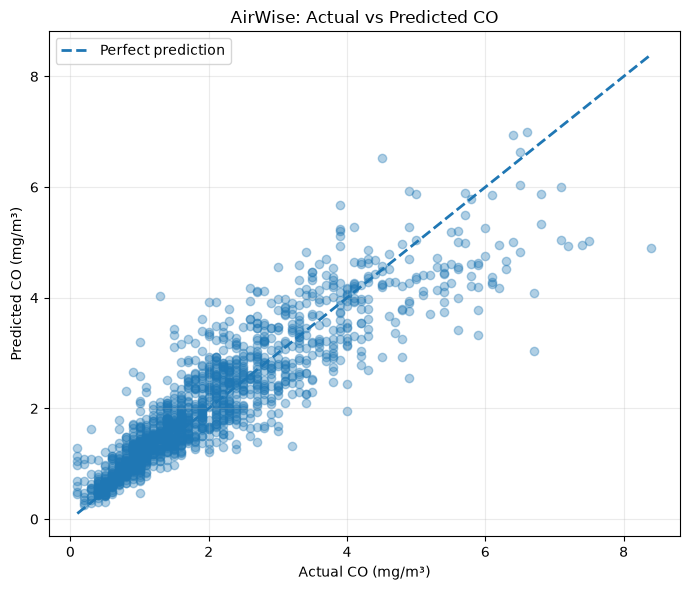

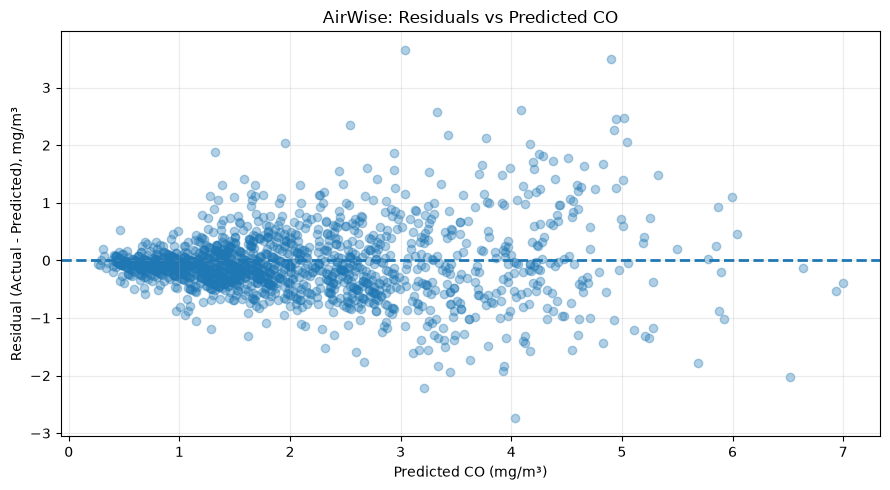

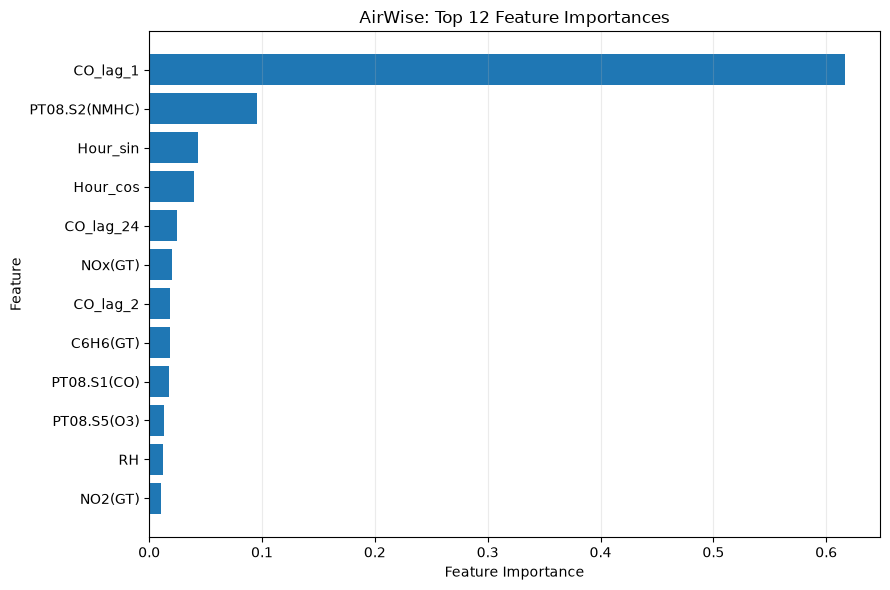


AIRWISE EVALUATION REPORT SAVED
Mean residual: -0.0659 mg/m³

Files saved in: c:\Users\mayan\OneDrive\Desktop\AIRWISE\visualizations

1. actual_vs_predicted_scatter.png
2. residuals_vs_predicted.png
3. feature_importance.png
4. model_evaluation_report.json
5. feature_importance.csv
6. model_comparison.csv
7. airwise_test_predictions.csv

Validated model bundle updated successfully.


In [7]:

# STEP 10: MODEL DIAGNOSTICS AND EVALUATION REPORT

import json
import matplotlib.pyplot as plt

# Recreate test results to ensure this cell works independently
test_results = pd.DataFrame({
    "Datetime": pd.to_datetime(test_dates.values),
    "Actual_CO": y_test.values,
    "Predicted_CO": rf_predictions
})

test_results["Residual"] = (
    test_results["Actual_CO"] - test_results["Predicted_CO"]
)

# Create visualizations folder
VISUAL_DIR = PROJECT_ROOT / "visualizations"
VISUAL_DIR.mkdir(parents=True, exist_ok=True)

# CHART 1: Actual vs Predicted scatter plot
plt.figure(figsize=(7, 6))

plt.scatter(
    test_results["Actual_CO"],
    test_results["Predicted_CO"],
    alpha=0.35
)

minimum = min(
    test_results["Actual_CO"].min(),
    test_results["Predicted_CO"].min()
)

maximum = max(
    test_results["Actual_CO"].max(),
    test_results["Predicted_CO"].max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    linewidth=2,
    label="Perfect prediction"
)

plt.title("AirWise: Actual vs Predicted CO")
plt.xlabel("Actual CO (mg/m³)")
plt.ylabel("Predicted CO (mg/m³)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "actual_vs_predicted_scatter.png",
    dpi=300
)
plt.show()


# CHART 2: Residuals vs Predicted values
plt.figure(figsize=(9, 5))

plt.scatter(
    test_results["Predicted_CO"],
    test_results["Residual"],
    alpha=0.35
)

plt.axhline(0, linestyle="--", linewidth=2)

plt.title("AirWise: Residuals vs Predicted CO")
plt.xlabel("Predicted CO (mg/m³)")
plt.ylabel("Residual (Actual - Predicted), mg/m³")
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "residuals_vs_predicted.png",
    dpi=300
)
plt.show()


# CHART 3: Feature importance
top_features = importance.head(12).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("AirWise: Top 12 Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "feature_importance.png",
    dpi=300
)
plt.show()


# Calculate average residual
mean_residual = float(test_results["Residual"].mean())

# Save evaluation metrics
evaluation_report = {
    "model": "Random Forest Regressor",
    "target": "Next-hour CO concentration",
    "unit": "mg/m3",
    "forecast_horizon_hours": 1,
    "training_observations": int(len(X_train)),
    "testing_observations": int(len(X_test)),
    "random_forest": {
        "mae": float(rf_mae),
        "rmse": float(rf_rmse),
        "r2": float(rf_r2)
    },
    "fair_comparison_observations": int(len(y_test_common)),
    "fair_comparison": {
        "random_forest": {
            "mae": float(rf_common_mae),
            "rmse": float(rf_common_rmse),
            "r2": float(rf_common_r2)
        },
        "persistence_baseline": {
            "mae": float(baseline_mae),
            "rmse": float(baseline_rmse),
            "r2": float(baseline_r2)
        }
    },
    "mean_residual": mean_residual
}

with open(
    VISUAL_DIR / "model_evaluation_report.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(evaluation_report, file, indent=4)


# Save feature importance
importance.to_csv(
    VISUAL_DIR / "feature_importance.csv",
    index=False
)

# Save test predictions
test_results.to_csv(
    VISUAL_DIR / "airwise_test_predictions.csv",
    index=False
)

# Save comparison table
comparison.to_csv(
    VISUAL_DIR / "model_comparison.csv",
    index=False
)

# Update validated model bundle with evaluation information
model_bundle["test_metrics"] = {
    "mae": float(rf_mae),
    "rmse": float(rf_rmse),
    "r2": float(rf_r2),
    "mean_residual": mean_residual
}

model_bundle["baseline_comparison"] = evaluation_report["fair_comparison"]

joblib.dump(
    model_bundle,
    validated_model_path
)

print("\nAIRWISE EVALUATION REPORT SAVED")
print("=" * 45)
print("Mean residual:", round(mean_residual, 4), "mg/m³")
print("\nFiles saved in:", VISUAL_DIR)
print("\n1. actual_vs_predicted_scatter.png")
print("2. residuals_vs_predicted.png")
print("3. feature_importance.png")
print("4. model_evaluation_report.json")
print("5. feature_importance.csv")
print("6. model_comparison.csv")
print("7. airwise_test_predictions.csv")
print("\nValidated model bundle updated successfully.")


In [8]:

# STEP 11: VERIFY SAVED MODEL

import joblib
import numpy as np

# Locate the saved model bundle
MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "airwise_co_forecast_validated.joblib"
)

# Check that the file exists
if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Validated model not found: {MODEL_PATH}"
    )

# Load the saved model
loaded_bundle = joblib.load(MODEL_PATH)

loaded_model = loaded_bundle["model"]
saved_features = loaded_bundle["feature_columns"]

# Verify feature compatibility
assert saved_features == feature_columns, (
    "Feature columns do not match!"
)

# Select one test observation
sample_input = X_test[saved_features].iloc[[0]]

# Generate a prediction using the reloaded model
sample_prediction = float(
    loaded_model.predict(sample_input)[0]
)

# Check that prediction is valid
assert np.isfinite(sample_prediction), (
    "Model generated an invalid prediction."
)

print("=" * 50)
print("AIRWISE MODEL VERIFICATION")
print("=" * 50)

print("Model loaded successfully!")
print("Feature count:", len(saved_features))
print("Model type:", type(loaded_model.named_steps["model"]).__name__)

print("\nTest observation:")
print("Forecast timestamp:", test_dates.iloc[0])

print("\nActual next-hour CO:",
      round(float(y_test.iloc[0]), 4), "mg/m³")

print("Predicted next-hour CO:",
      round(sample_prediction, 4), "mg/m³")

print("\nSaved evaluation metrics:")
print(loaded_bundle.get("test_metrics"))

print("\nMODEL VERIFICATION SUCCESSFUL!")


AIRWISE MODEL VERIFICATION
Model loaded successfully!
Feature count: 21
Model type: RandomForestRegressor

Test observation:
Forecast timestamp: 2005-01-29 07:00:00

Actual next-hour CO: 0.5 mg/m³
Predicted next-hour CO: 0.4276 mg/m³

Saved evaluation metrics:
{'mae': 0.40868716308483405, 'rmse': 0.5902555244262797, 'r2': 0.8072710437151919, 'mean_residual': -0.06590634292417681}

MODEL VERIFICATION SUCCESSFUL!
